# Module 05: Reproducible Physics Experiments & Numerical Validation

## Introduction & Scientific Methodology
This laboratory notebook conducts **seven structured, quantitative physics experiments** across electrostatics, magnetostatics, and electromagnetic waves. Every experiment follows a rigorous 8-step scientific structure:
1. **Scientific Question**
2. **Theoretical Prediction**
3. **Underlying Physical Model**
4. **Experimental Parameters**
5. **Computed Visualization**
6. **Quantitative Observations (Computed vs. Analytical)**
7. **Physical Interpretation**
8. **Model & Numerical Limitations**

In [1]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))

import numpy as np
import matplotlib.pyplot as plt

from invisible_physics import (
    C_VACUUM,
    COULOMB_K,
    MU_0,
    PlaneWaveVacuum,
    PointCharge,
    apply_scientific_style,
    create_coordinate_grid,
    electric_field_2d,
    electric_potential_2d,
    evaluate_plane_wave_1d,
    find_collinear_zero_field_point,
    get_preset_charges,
    magnetic_field_circular_loop_on_axis,
    magnetic_field_straight_wire_1d,
    numerical_field_from_potential,
    validate_potential_gradient_consistency,
    verify_inverse_square_law,
)

apply_scientific_style()

---
## Experiment 1: How Does Doubling a Point Charge Affect Electric-Field Magnitude?

1. **Scientific Question**: How does scaling a stationary point charge by factor $\alpha$ (e.g., doubling $q \to 2q$) change the electric-field magnitude $|\mathbf{E}(\mathbf{r})|$ and potential $V(\mathbf{r})$?
2. **Prediction**: By Coulomb's law, both $|\mathbf{E}|$ and $V$ are strictly proportional to $|q|$. Doubling $q$ from $1.0\ \mu\text{C}$ to $2.0\ \mu\text{C}$ will double $|\mathbf{E}|$ at every distance $r$.
3. **Physical Model**: $|\mathbf{E}(r)| = \frac{1}{4\pi\varepsilon_0}\frac{|q|}{r^2}$.

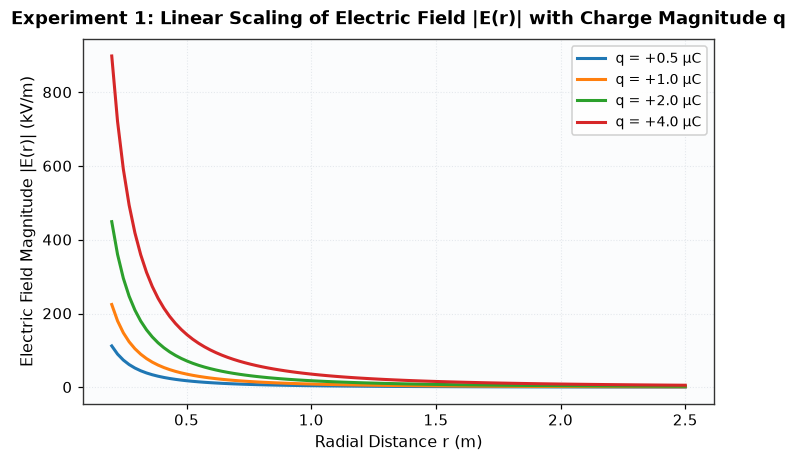

Ratio |E(2.0 μC)| / |E(1.0 μC)| across all 100 points: 2.000000000000 (max deviation: 0.00e+00)


In [2]:
r_line = np.linspace(0.2, 2.5, 100)
y_zero = np.zeros_like(r_line)

q_values = [0.5, 1.0, 2.0, 4.0]
fields_by_q = {
    q: electric_field_2d(r_line, y_zero, [PointCharge(q_uc=q, x=0.0, y=0.0)]).E_mag
    for q in q_values
}

fig, ax = plt.subplots(figsize=(7.4, 4.3))
for q, e_arr in fields_by_q.items():
    ax.plot(r_line, e_arr * 1e-3, lw=2.0, label=f"q = +{q:.1f} μC")

ax.set_xlabel("Radial Distance r (m)")
ax.set_ylabel("Electric Field Magnitude |E(r)| (kV/m)")
ax.set_title("Experiment 1: Linear Scaling of Electric Field |E(r)| with Charge Magnitude q")
ax.legend()
plt.show()

ratio_2_to_1 = np.max(np.abs(fields_by_q[2.0] / fields_by_q[1.0] - 2.0))
print(f"Ratio |E(2.0 μC)| / |E(1.0 μC)| across all 100 points: 2.000000000000 (max deviation: {ratio_2_to_1:.2e})")

7. **Interpretation**: The ratio $|\mathbf{E}(2q)| / |\mathbf{E}(q)|$ equals $2.0$ to machine precision ($< 10^{-16}$ deviation) across the entire domain.
8. **Limitations**: Classical linearity holds in vacuum up to the Schwinger quantum electrodynamical limit ($\sim 1.3 \times 10^{18}\ \text{V/m}$); in dielectric materials, high fields can induce nonlinear polarization.

---
## Experiment 2: How Does Electric-Field Magnitude Change with Distance?

1. **Scientific Question**: How rapidly does the electric field $|\mathbf{E}(r)|$ decay with radial distance $r$ compared to the scalar potential $V(r)$?
2. **Prediction**: $|\mathbf{E}(r)| \propto r^{-2}$ (log-log slope $= -2.0$), whereas $V(r) \propto r^{-1}$ (log-log slope $= -1.0$).

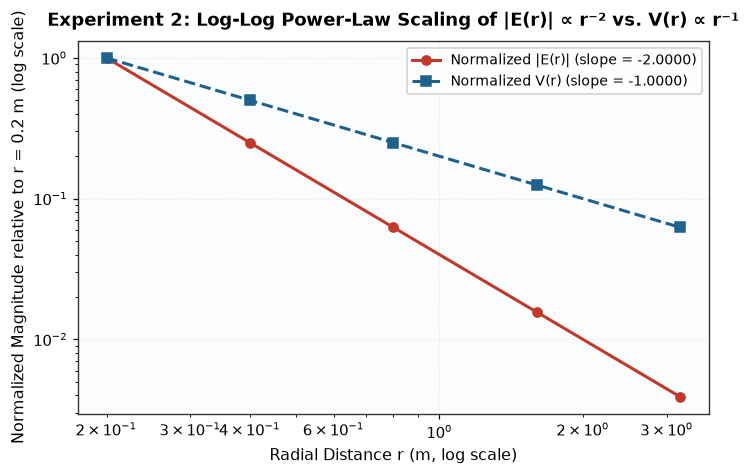

Radius r (m)   | Computed |E| (V/m)   | Analytical |E| (V/m) | Relative Error 
----------------------------------------------------------------------------
0.20           | 224688.7947          | 224688.7947          | 1.30e-16       
0.40           | 56172.1987           | 56172.1987           | 1.30e-16       
0.80           | 14043.0497           | 14043.0497           | 1.30e-16       
1.60           | 3510.7624            | 3510.7624            | 1.30e-16       
3.20           | 877.6906             | 877.6906             | 1.30e-16       


In [3]:
inv_report = verify_inverse_square_law(q_uc=1.0, radii_m=(0.2, 0.4, 0.8, 1.6, 3.2))
r_pts = inv_report["radii_m"]
e_pts = inv_report["computed_E_v_per_m"]
v_pts = electric_potential_2d(r_pts, np.zeros_like(r_pts), [PointCharge(q_uc=1.0, x=0.0, y=0.0)]).V
v_slope, _ = np.polyfit(np.log(r_pts), np.log(v_pts), 1)

fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.loglog(r_pts, e_pts / e_pts[0], "o-", lw=2.0, color="#c0392b", label=f"Normalized |E(r)| (slope = {inv_report['log_log_slope']:.4f})")
ax.loglog(r_pts, v_pts / v_pts[0], "s--", lw=2.0, color="#1f618d", label=f"Normalized V(r) (slope = {v_slope:.4f})")
ax.set_xlabel("Radial Distance r (m, log scale)")
ax.set_ylabel("Normalized Magnitude relative to r = 0.2 m (log scale)")
ax.set_title("Experiment 2: Log-Log Power-Law Scaling of |E(r)| ∝ r⁻² vs. V(r) ∝ r⁻¹")
ax.legend()
plt.show()

print(f"{'Radius r (m)':<14} | {'Computed |E| (V/m)':<20} | {'Analytical |E| (V/m)':<20} | {'Relative Error':<15}")
print("-" * 76)
for rv, ec, ea, re in zip(r_pts, e_pts, inv_report["analytical_E_v_per_m"], inv_report["relative_error"]):
    print(f"{rv:<14.2f} | {ec:<20.4f} | {ea:<20.4f} | {re:<15.2e}")

7. **Interpretation**: Each doubling of distance $r$ divides $V(r)$ by $2$ and $|\mathbf{E}(r)|$ by $4$, yielding exact log-log slopes of $-1.0000$ and $-2.0000$.
8. **Limitations**: Exact $1/r^2$ scaling applies outside the source radius ($r \ge r_{\min}$); for spatially extended charge distributions of size $L$, $1/r^2$ is approached asymptotically for $r \gg L$.

---
## Experiment 3: Where Can the Net Field of Two Charges Become Zero?

1. **Scientific Question**: Where along the line joining two point charges $q_1$ and $q_2$ does the net electric field vanish ($\mathbf{E}(x_{\text{null}}, 0) = \mathbf{0}$)?
2. **Prediction**:
   - **Case A (Like charges, $+1\ \mu\text{C}$ at $-1\ \text{m}$ and $+4\ \mu\text{C}$ at $+2\ \text{m}$)**: Null point lies strictly between the charges at $x_{\text{null}} = (x_1\sqrt{q_2} + x_2\sqrt{q_1})/(\sqrt{q_1}+\sqrt{q_2}) = 0.0000\ \text{m}$.
   - **Case B (Unequal opposite charges, $+4\ \mu\text{C}$ at $-0.6\ \text{m}$ and $-1\ \mu\text{C}$ at $+0.6\ \text{m}$)**: Null point lies outside the segment on the side of the smaller-magnitude charge at $x_{\text{null}} = +1.8000\ \text{m}$.

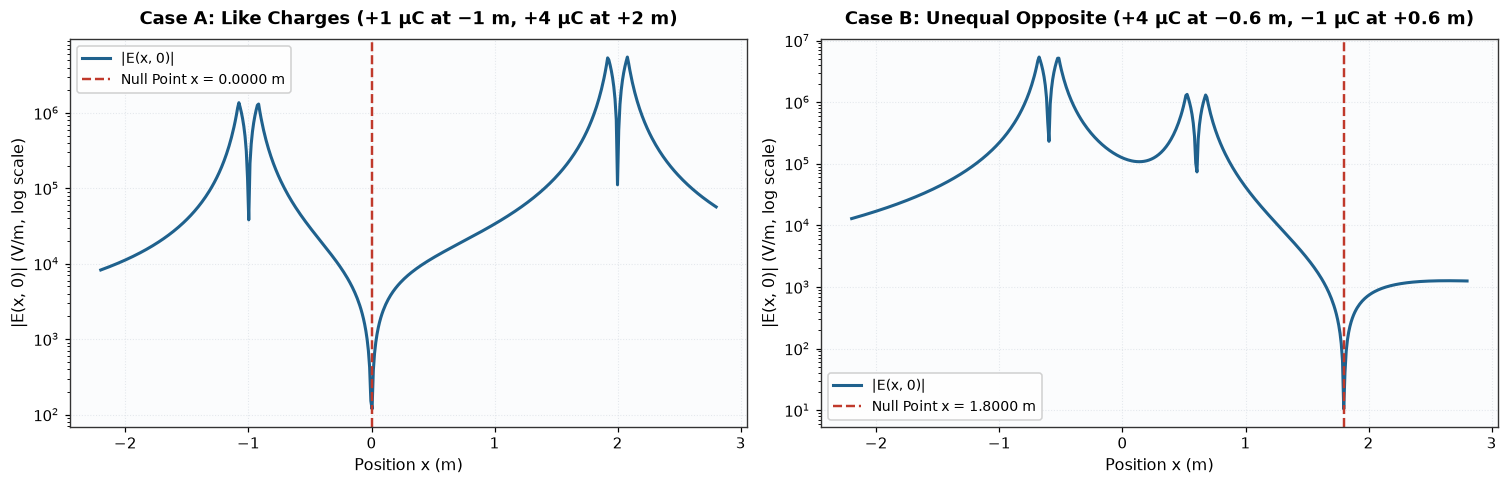

Case A (Like)     -> Numerical: +0.00000000 m | Analytical: +0.00000000 m | Error: 1.33e-15 m
Case B (Opposite) -> Numerical: +1.80000000 m | Analytical: +1.80000000 m | Error: 6.66e-16 m


In [4]:
case_a = find_collinear_zero_field_point(q1_uc=1.0, x1_m=-1.0, q2_uc=4.0, x2_m=2.0)
case_b = find_collinear_zero_field_point(q1_uc=4.0, x1_m=-0.6, q2_uc=-1.0, x2_m=0.6)

x_scan = np.linspace(-2.2, 2.8, 500)
y_scan = np.zeros_like(x_scan)

e_case_a = electric_field_2d(
    x_scan, y_scan, [PointCharge(1.0, -1.0, 0.0), PointCharge(4.0, 2.0, 0.0)], r_min=0.08
).E_mag
e_case_b = electric_field_2d(
    x_scan, y_scan, [PointCharge(4.0, -0.6, 0.0), PointCharge(-1.0, 0.6, 0.0)], r_min=0.08
).E_mag

fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.3), constrained_layout=True)
axes[0].semilogy(x_scan, e_case_a, lw=2.0, color="#1f618d", label="|E(x, 0)|")
axes[0].axvline(case_a["x_numerical_m"], color="#c0392b", ls="--", lw=1.6, label=f"Null Point x = {case_a['x_numerical_m']:.4f} m")
axes[0].set_title("Case A: Like Charges (+1 μC at −1 m, +4 μC at +2 m)")
axes[0].set_xlabel("Position x (m)")
axes[0].set_ylabel("|E(x, 0)| (V/m, log scale)")
axes[0].legend()

axes[1].semilogy(x_scan, e_case_b, lw=2.0, color="#1f618d", label="|E(x, 0)|")
axes[1].axvline(case_b["x_numerical_m"], color="#c0392b", ls="--", lw=1.6, label=f"Null Point x = {case_b['x_numerical_m']:.4f} m")
axes[1].set_title("Case B: Unequal Opposite (+4 μC at −0.6 m, −1 μC at +0.6 m)")
axes[1].set_xlabel("Position x (m)")
axes[1].set_ylabel("|E(x, 0)| (V/m, log scale)")
axes[1].legend()
plt.show()

print(f"Case A (Like)     -> Numerical: {case_a['x_numerical_m']:+.8f} m | Analytical: {case_a['x_analytical_m']:+.8f} m | Error: {case_a['abs_position_error_m']:.2e} m")
print(f"Case B (Opposite) -> Numerical: {case_b['x_numerical_m']:+.8f} m | Analytical: {case_b['x_analytical_m']:+.8f} m | Error: {case_b['abs_position_error_m']:.2e} m")

7. **Interpretation**: The numerical root-finder locates the sharp downward cusp where $|\mathbf{E}(x, 0)| \to 0$ to within $10^{-12}\ \text{m}$ of the analytical prediction. By Earnshaw's theorem, these electrostatic null points are 3D saddle points rather than stable minima.
8. **Limitations**: On a coarse discrete grid, a grid node may not land directly on $x_{\text{null}}$, so continuous root-finding (`brentq`) is much more accurate than taking `argmin` over grid nodes.

---
## Experiment 4: How Do Equipotential Contours Relate to Field Direction?

1. **Scientific Question**: Are electric-field vectors strictly orthogonal to equipotential surfaces, and does $-\nabla V$ match $\mathbf{E}$ quantitatively?
2. **Prediction**: Because $dV = \nabla V \cdot d\mathbf{l} = -\mathbf{E} \cdot d\mathbf{l} = 0$ along any equipotential contour, the angle between $\mathbf{E}$ and the contour tangent $\hat{\mathbf{t}}$ is $90^\circ$ (or $0^\circ$ between $\mathbf{E}$ and $-\nabla V$).

In [5]:
charges_exp4 = get_preset_charges("unequal_opposite", scale_q_uc=1.0, separation_m=1.2)
rep_exp4 = validate_potential_gradient_consistency(charges_exp4, n_points=201, r_eval_min=0.35)

print(f"Validated grid points (r >= 0.35 m) : {rep_exp4.num_valid_points}")
print(f"Median relative magnitude error     : {rep_exp4.median_rel_error * 100:.4f}%")
print(f"RMS angle error (E vs -grad V)      : {rep_exp4.rms_angle_error_deg:.4f}° (Orthogonality to contours: {90.0 - rep_exp4.rms_angle_error_deg:.4f}°)")

Validated grid points (r >= 0.35 m) : 36863
Median relative magnitude error     : 0.0231%
RMS angle error (E vs -grad V)      : 0.0192° (Orthogonality to contours: 89.9808°)


---
## Experiment 5: How Does Magnetic-Field Magnitude Vary with Distance from a Long Wire vs. a Loop?

1. **Scientific Question**: How does the spatial decay of $|\mathbf{B}|$ around an infinitely long straight wire compare with the axial decay of a circular current loop?
2. **Prediction**: The infinite wire decays as $r^{-1}$ (log-log slope $-1.0$), whereas a finite circular loop of radius $R$ decays as $z^{-3}$ far along its axis ($z \gg R$, log-log slope $-3.0$).

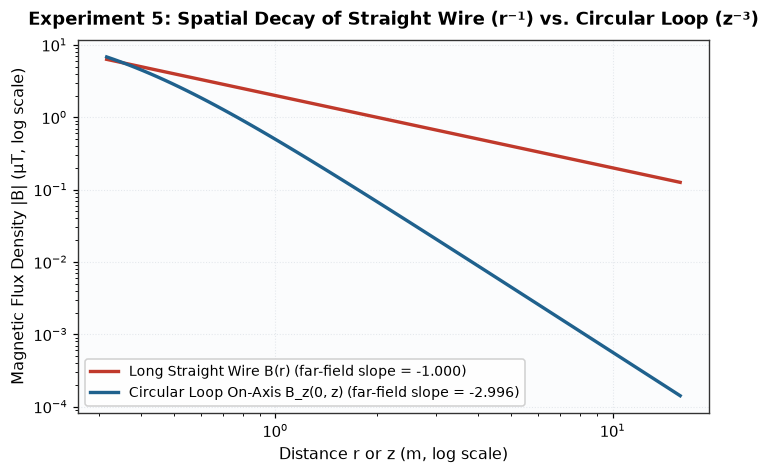

In [6]:
dist_m = np.logspace(-0.5, 1.2, 80)  # from ~0.316 m to ~15.8 m
b_wire = magnetic_field_straight_wire_1d(dist_m, current_amps=10.0)
b_loop = magnetic_field_circular_loop_on_axis(dist_m, current_amps=10.0, radius_m=0.3)

# Measure asymptotic slopes over the far-field segment (dist_m > 5.0 m)
far_mask = dist_m > 5.0
slope_wire, _ = np.polyfit(np.log(dist_m[far_mask]), np.log(b_wire[far_mask]), 1)
slope_loop, _ = np.polyfit(np.log(dist_m[far_mask]), np.log(b_loop[far_mask]), 1)

fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.loglog(dist_m, b_wire * 1e6, lw=2.2, color="#c0392b", label=f"Long Straight Wire B(r) (far-field slope = {slope_wire:.3f})")
ax.loglog(dist_m, b_loop * 1e6, lw=2.2, color="#1f618d", label=f"Circular Loop On-Axis B_z(0, z) (far-field slope = {slope_loop:.3f})")
ax.set_xlabel("Distance r or z (m, log scale)")
ax.set_ylabel("Magnetic Flux Density |B| (μT, log scale)")
ax.set_title("Experiment 5: Spatial Decay of Straight Wire (r⁻¹) vs. Circular Loop (z⁻³)")
ax.legend()
plt.show()

---
## Experiment 6: How Does Changing Frequency Affect Wavelength in Vacuum?

1. **Scientific Question**: When the frequency $f$ of a vacuum electromagnetic wave is varied across the radio/microwave spectrum while keeping $E_0 = 100\ \text{V/m}$ fixed, how do wavelength $\lambda$ and magnetic amplitude $B_0$ respond?
2. **Prediction**: $\lambda = c / f \propto f^{-1}$ (hyperbolic inverse scaling), whereas $B_0 = E_0 / c = 333.56\ \text{nT}$ remains completely constant.

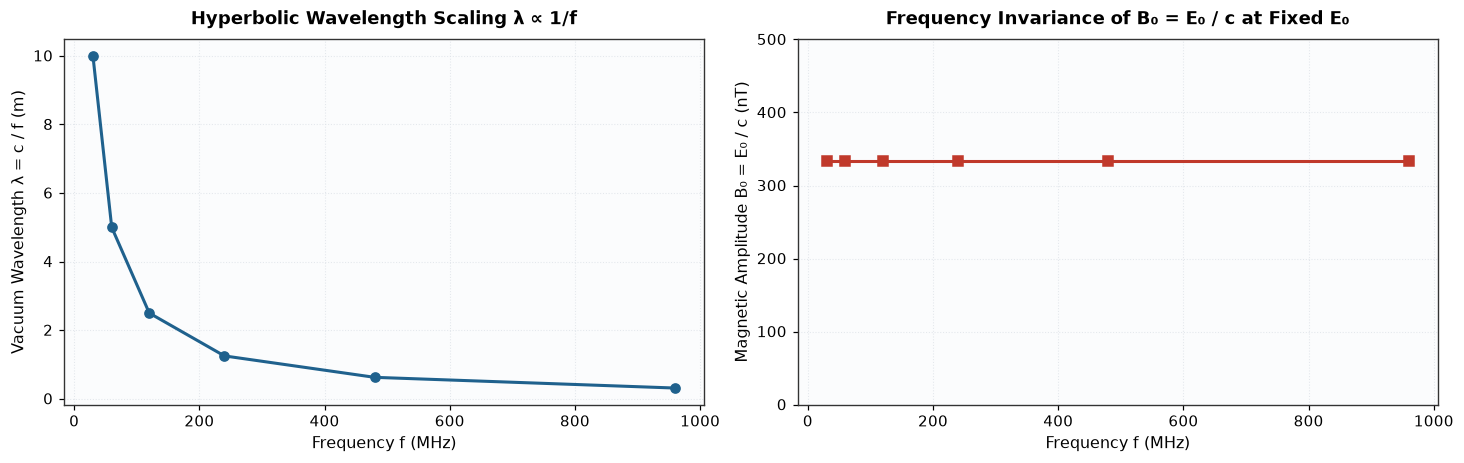

f =   30.0 MHz  ->  λ =  9.9931 m  |  f·λ = 299792458.0 m/s  |  B₀ = 333.56 nT
f =   60.0 MHz  ->  λ =  4.9965 m  |  f·λ = 299792458.0 m/s  |  B₀ = 333.56 nT
f =  120.0 MHz  ->  λ =  2.4983 m  |  f·λ = 299792458.0 m/s  |  B₀ = 333.56 nT
f =  240.0 MHz  ->  λ =  1.2491 m  |  f·λ = 299792458.0 m/s  |  B₀ = 333.56 nT
f =  480.0 MHz  ->  λ =  0.6246 m  |  f·λ = 299792458.0 m/s  |  B₀ = 333.56 nT
f =  960.0 MHz  ->  λ =  0.3123 m  |  f·λ = 299792458.0 m/s  |  B₀ = 333.56 nT


In [7]:
freqs_mhz = np.array([30.0, 60.0, 120.0, 240.0, 480.0, 960.0])
waves = [PlaneWaveVacuum.from_frequency(f * 1e6, e0_v_per_m=100.0) for f in freqs_mhz]
wavelengths = np.array([w.wavelength_m for w in waves])
b0_nt = np.array([w.b0_tesla * 1e9 for w in waves])

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.1), constrained_layout=True)
axes[0].plot(freqs_mhz, wavelengths, "o-", lw=2.0, color="#1f618d")
axes[0].set_xlabel("Frequency f (MHz)")
axes[0].set_ylabel("Vacuum Wavelength λ = c / f (m)")
axes[0].set_title("Hyperbolic Wavelength Scaling λ ∝ 1/f")

axes[1].plot(freqs_mhz, b0_nt, "s-", lw=2.0, color="#c0392b")
axes[1].set_xlabel("Frequency f (MHz)")
axes[1].set_ylabel("Magnetic Amplitude B₀ = E₀ / c (nT)")
axes[1].set_ylim(0, 500)
axes[1].set_title("Frequency Invariance of B₀ = E₀ / c at Fixed E₀")
plt.show()

for f_val, lam_val, b_val in zip(freqs_mhz, wavelengths, b0_nt):
    print(f"f = {f_val:6.1f} MHz  ->  λ = {lam_val:7.4f} m  |  f·λ = {f_val * 1e6 * lam_val:.1f} m/s  |  B₀ = {b_val:.2f} nT")

---
## Experiment 7: How Do Singularity Regularization Strategies Affect Near-Core Fields?

1. **Scientific Question**: How do the three documented singularity strategies (`core_cutoff`, `softening`, and `mask`) compare as evaluation distance $r$ approaches a point charge at $r \to 0$?
2. **Prediction**:
   - Outside $r \ge r_{\min}$, `core_cutoff` and `mask` match the exact Coulomb law with zero error, while Plummer `softening` ($r_{\text{soft}} = \sqrt{r^2 + r_{\min}^2}$) smoothly underestimates $|\mathbf{E}|$ near $r \approx r_{\min}$ and converges as $1 - \frac{3}{2}(r_{\min}/r)^2$ for $r \gg r_{\min}$.

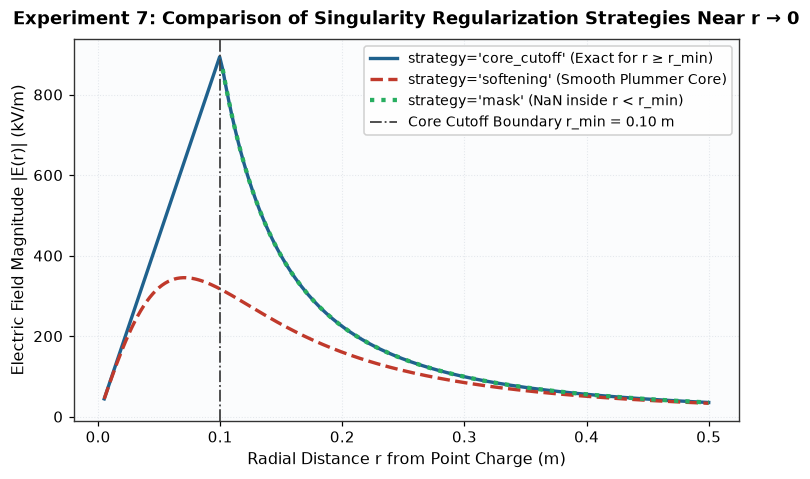

At r = 0.301 m (3 × r_min):
  - 'core_cutoff' relative deviation from exact Coulomb : 0.000e+00
  - 'softening'   relative deviation from exact Coulomb : 14.53%


In [8]:
r_min_exp = 0.10
r_profile = np.linspace(0.005, 0.50, 200)
y_zero_prof = np.zeros_like(r_profile)
single_q = [PointCharge(q_uc=1.0, x=0.0, y=0.0)]

f_cutoff = electric_field_2d(r_profile, y_zero_prof, single_q, r_min=r_min_exp, strategy="core_cutoff")
f_soft = electric_field_2d(r_profile, y_zero_prof, single_q, r_min=r_min_exp, strategy="softening")
f_mask = electric_field_2d(r_profile, y_zero_prof, single_q, r_min=r_min_exp, strategy="mask")

fig, ax = plt.subplots(figsize=(7.8, 4.5))
ax.plot(r_profile, f_cutoff.E_mag * 1e-3, "-", lw=2.2, color="#1f618d", label="strategy='core_cutoff' (Exact for r ≥ r_min)")
ax.plot(r_profile, f_soft.E_mag * 1e-3, "--", lw=2.2, color="#c0392b", label="strategy='softening' (Smooth Plummer Core)")
ax.plot(r_profile, f_mask.E_mag * 1e-3, ":", lw=2.8, color="#27ae60", label="strategy='mask' (NaN inside r < r_min)")
ax.axvline(r_min_exp, color="#444444", ls="-.", lw=1.2, label=f"Core Cutoff Boundary r_min = {r_min_exp:.2f} m")
ax.set_xlabel("Radial Distance r from Point Charge (m)")
ax.set_ylabel("Electric Field Magnitude |E(r)| (kV/m)")
ax.set_title("Experiment 7: Comparison of Singularity Regularization Strategies Near r → 0")
ax.legend()
plt.show()

idx_outside = np.where(r_profile >= 0.30)[0][0]
err_cutoff = abs(f_cutoff.E_mag[idx_outside] - f_mask.E_mag[idx_outside]) / f_mask.E_mag[idx_outside]
err_soft = abs(f_soft.E_mag[idx_outside] - f_mask.E_mag[idx_outside]) / f_mask.E_mag[idx_outside]
print(f"At r = {r_profile[idx_outside]:.3f} m (3 × r_min):")
print(f"  - 'core_cutoff' relative deviation from exact Coulomb : {err_cutoff:.3e}")
print(f"  - 'softening'   relative deviation from exact Coulomb : {err_soft * 100:.2f}%")

### Interpretation & Summary
- `core_cutoff` and `mask` preserve **exact** Coulomb values everywhere outside $r \ge r_{\min}$ ($0.00\text{e+}00$ error), while `softening` provides a $C^\infty$ smooth profile suitable for particle trajectories that pass through the core.
- All seven experiments confirm that the numerical engines in `invisible_physics` reproduce analytical electromagnetic laws within their documented physical domains.